In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
file_path="C:\\Users\\user\\Downloads\\archive\\EasyVisa.csv"
visa_df=pd.read_csv(file_path)
visa_df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified


**how to get a one specific column**

In [70]:
visa_df.continent #series  type no title

0          Asia
1          Asia
2          Asia
3          Asia
4        Africa
          ...  
25475      Asia
25476      Asia
25477      Asia
25478      Asia
25479      Asia
Name: continent, Length: 25480, dtype: object

In [9]:
print(visa_df['continent'])# same as series
type(visa_df['continent'])

0          Asia
1          Asia
2          Asia
3          Asia
4        Africa
          ...  
25475      Asia
25476      Asia
25477      Asia
25478      Asia
25479      Asia
Name: continent, Length: 25480, dtype: object


pandas.core.series.Series

**to get dataframe**

In [11]:
cols=["continent"]
visa_df[cols] #this is dataframe extra square

,continent
0,Asia
1,Asia
2,Asia
3,Asia
4,Africa
...,...
25475,Asia
25476,Asia
25477,Asia
25478,Asia


In [13]:
visa_df[["continent"]] #cols=["continent"]  visa_df[cols]   same o/p

,continent
0,Asia
1,Asia
2,Asia
3,Asia
4,Africa
...,...
25475,Asia
25476,Asia
25477,Asia
25478,Asia


**to get 2 or more cols**

In [16]:
cols=["continent","case_status"]
visa_df[cols]

,continent,case_status
0,Asia,Denied
1,Asia,Certified
2,Asia,Denied
3,Asia,Denied
4,Africa,Certified
...,...,...
25475,Asia,Certified
25476,Asia,Certified
25477,Asia,Certified
25478,Asia,Certified


$Unique()$
- first read the column 
- then apply unique to get unique labels
- it is a series type not in dataframe
- return in array format

In [18]:
visa_df["continent"].unique()

array(['Asia', 'Africa', 'North America', 'Europe', 'South America',
       'Oceania'], dtype=object)

$nunique()$
 - return the count of the unique labels

In [22]:
len(visa_df["continent"]) #25480 are total labels outof wich only 6 are unique

25480

In [23]:
visa_df["continent"].nunique() #6

6

**out of 6 unique labels how many are asia,afria,...3etc**

In [26]:
visa_df[["continent"]]=="Asia"

,continent
0,True
1,True
2,True
3,True
4,False
...,...
25475,True
25476,True
25477,True
25478,True


**to get only Dataframe that contain ASIA**

In [7]:
visa_df[visa_df["continent"]=="Asia"]

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
5,EZYV06,Asia,Master's,Y,N,2339,2012,South,78252.1400,Year,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...,...
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.5700,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.7900,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.8500,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.7700,Year,Y,Certified


In [8]:
len(visa_df[visa_df["continent"]=="Asia"])  # out of 25480 16861 are asia

16861

In [9]:
continents=list(visa_df.continent.unique())
continents

['Asia', 'Africa', 'North America', 'Europe', 'South America', 'Oceania']

In [10]:
count=[]
for i in continents:
    count.append(len(visa_df[visa_df["continent"]==i]))
count

[16861, 551, 3292, 3732, 852, 192]

In [11]:
cols=["continents","count",]
continent_df=pd.DataFrame(zip(continents,count),columns=cols) # frequncy table
continent_df

,continents,count
0,Asia,16861
1,Africa,551
2,North America,3292
3,Europe,3732
4,South America,852
5,Oceania,192


**save continent_df in local**

In [12]:
continent_df.to_csv("C:\\Users\\user\\Downloads\\archive\\continent_df.csv")

**save where current .ipynb file is present**

In [13]:
continent_df.to_csv("continent_info.csv",index=False)

$Value-counts$
- it is a series type 

In [14]:
visa_df.continent.value_counts()

continent
Asia             16861
Europe            3732
North America     3292
South America      852
Africa             551
Oceania            192
Name: count, dtype: int64

**how to create a dataframe from the value_counts(which is a series type)**
- in order to crearte a dataframe we need
- two list or one dictionary
- from value_counts create two lists(index,keys)

In [15]:
visa_df.continent.value_counts().index

Index(['Asia', 'Europe', 'North America', 'South America', 'Africa',
       'Oceania'],
      dtype='object', name='continent')

In [16]:
visa_df.continent.value_counts().values

array([16861,  3732,  3292,   852,   551,   192])

In [27]:
#method 1 using value_count method extract array/list 
continents=visa_df.continent.value_counts().index
count=visa_df.continent.value_counts().values
cols=["continents","counts"]
continent_data=pd.DataFrame(zip(continents,count),columns=cols)
continent_data

,continents,counts
0,Asia,16861
1,Europe,3732
2,North America,3292
3,South America,852
4,Africa,551
5,Oceania,192


In [18]:
#method 2 convert into dict and directly create dataframe
dict1=dict(visa_df.continent.value_counts())
dict1

{'Asia': np.int64(16861),
 'Europe': np.int64(3732),
 'North America': np.int64(3292),
 'South America': np.int64(852),
 'Africa': np.int64(551),
 'Oceania': np.int64(192)}

In [19]:
pd.DataFrame(dict1,index=["count"])

,Asia,Europe,North America,South America,Africa,Oceania
count,16861,3732,3292,852,551,192


In [22]:
#method 3
dict1=dict(visa_df.continent.value_counts())
keys=dict1.keys()
values=dict1.values()
cols=["continents","count"]
pd.DataFrame(zip(keys,values),columns=cols)

,continents,count
0,Asia,16861
1,Europe,3732
2,North America,3292
3,South America,852
4,Africa,551
5,Oceania,192


**bar plots**
- require x and y axis
- x:categorical data
- y:numerical data
- data name===continent_df or continent_info
- plt.bar() take mainly 3 args
- xaxis= x, heigh=yaxis, data=data_name
- use value_counts method it will display in order 

<BarContainer object of 6 artists>

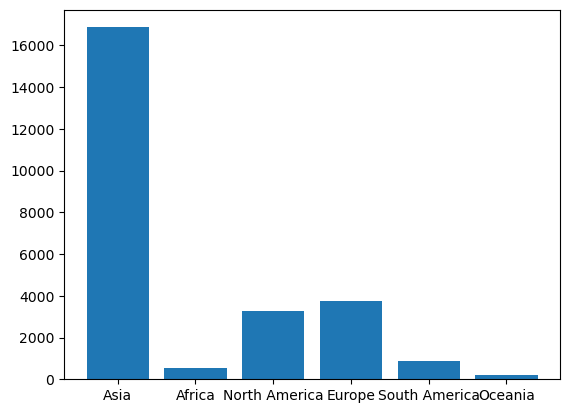

In [32]:
plt.bar("continents","count",data=continent_df) # it is from sractch

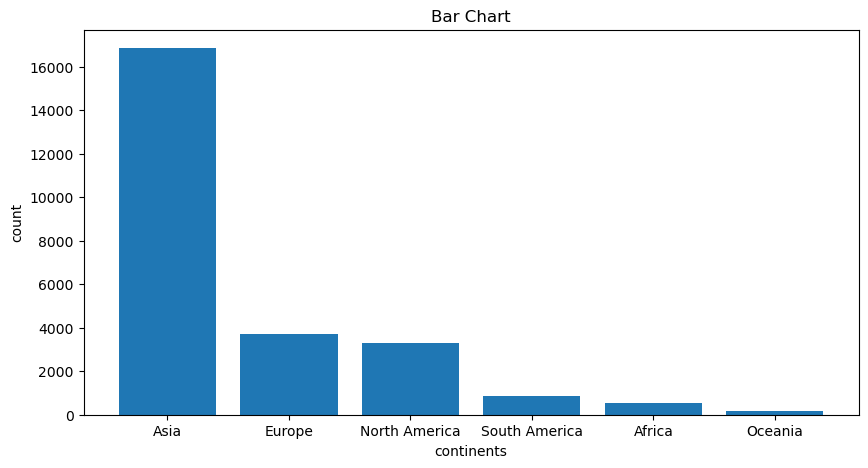

In [42]:
plt.figure(figsize=(10,5))
#10 horizontal x axis
#5  vertical y axis
plt.bar("continents","counts",data=continent_data) # it is from value_count() method will return in increning order
plt.title("Bar Chart")
plt.xlabel("continents")
plt.ylabel("count")
plt.savefig("continent_bar.jpg")
plt.show()